<a href="https://colab.research.google.com/github/nrannisak2/2026_Intro_Python/blob/main/FEEDBACK_NURANNISA_Exercise_Env_1_4_matplotlib_and_xarray_environmental_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.4-matplotlib-and-xarray-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

## Compelling Challenge

Visualization is my favourite part of Python programming, but it is also one of the areas I struggle with the most. While working through this exercise, I encountered several bugs and challenges in reproducing the provided visualizations, particularly in **Exercises 2 and 3.**

The two Markdown files corresponding to the questions which code answers produced unexpected errors are available on the page below.

In [ ]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

In [ ]:
# Pre-supplied: run this first.
import numpy as np
import matplotlib.pyplot as plt

## Exercise 2: Global surface air temperature and its zonal mean

The three files cached below hold one snapshot of surface air temperature from the
[NCEP/NCAR atmospheric reanalysis 1](https://psl.noaa.gov/data/gridded/data.ncep.reanalysis.html),
as plain numpy arrays: `lon` (192 longitudes), `lat` (94 latitudes, running north to south), and
`temp_kelvin`, the field itself with shape `(94, 192)` — **in kelvin**.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-global-temperature.png" alt="A filled contour map of global surface air temperature in magma colours with a white dashed contour at minus ten degrees, beside a line plot of the zonal mean against latitude" width="100%">

<em>The figure to replicate. Left: the field as filled contours, with a single white contour drawn
at −10 °C. Right: the zonal mean — the average along longitude — against latitude.</em>


Rebuild it, and say in a comment which hemisphere's winter this snapshot was taken in, and how
the zonal mean tells you.

## **Challenge and unexpected Errors: global surface temperature plot did not map the reference.**

In the first version:
* I drew `imshow` together with `contourf` (copied the codes from another assignment), where imshow uses pixel indices (and flips the y-axis), so the map was shown in the wrong coordinates, partially cropped and upside down, and the colorbar came from imshow instead of from the contour plot. In addition, only part of the world is visible. The southern hemisphere and everything else outside the pixel window are cut off.
* For the surface-temperature figure I wanted a filled contour map with a dashed white line at -10 °C, next to a zonal-mean profile. My first attempt gave a map that was cropped, upside down and colored with the wrong colorbar, and it had no white line. There is no dashed white line. `contour_level=[-10]` isn’t a valid argument, (In current matplotlib the invalid keyword raises an `AttributeError`.) so it does nothing. The -10 °C line needs its own `ax[0].contour(...)` call.

The fix:
* **Removed `imshow`.** The map should be drawn by `contourf` alone. `imshow` switched the axes to pixel indices, flipped the y-axis and added its own colormap, so it was incompatible with a plot in longitude and latitude. Each map layer now uses coordinates that are real degrees.
* **Drew the -10 °C line with its own `contour` call.** `contourf` fills regions and does not accept a `contour_level` argument, so the line needs `ax.contour(lon, lat, temp_c, levels=[-10], colors="w")`.
* **Built the colorbar from the `contourf` result.** I stored the output as `cf` and called `fig.colorbar(cf, ax=ax[0], ...)`, so the colorbar shows the magma levels from -30 to 40   that the map uses, instead of the default colormap of the removed `imshow`.

In [ ]:
# Pre-supplied: download the three arrays and cache them locally.
import pooch

In [ ]:
base_url = "https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/"

In [ ]:
path_lon = pooch.retrieve(
    url=base_url + "ncep_global_temp_lon.npy",
    known_hash="sha256:eaf54b88dd89279d3034da17fe8470dc2c841bf9fa89b2aa741dacff9c326cdb",
    fname="ncep_global_temp_lon.npy",
    path=pooch.os_cache("mlees"),
)
path_lat = pooch.retrieve(
    url=base_url + "ncep_global_temp_lat.npy",
    known_hash="sha256:af1f438080460e1fca4583b2ec19b44285a3d3776e4d21b8da9b6e162906c88a",
    fname="ncep_global_temp_lat.npy",
    path=pooch.os_cache("mlees"),
)
path_temp = pooch.retrieve(
    url=base_url + "ncep_global_temp_kelvin.npy",
    known_hash="sha256:e040ca257334708b43e86398e09a5669fcf051179ecf5dcd278f758d67beed20",
    fname="ncep_global_temp_kelvin.npy",
    path=pooch.os_cache("mlees"),
)

/tmp/ipykernel_949/3699699989.py:9: UserWarning: The following kwargs were not used by contour: 'contour_level'
  ax[0].contourf(lon, lat, temp_c, levels=np.linspace(-30, 40, 15), cmap="magma", extend="both",


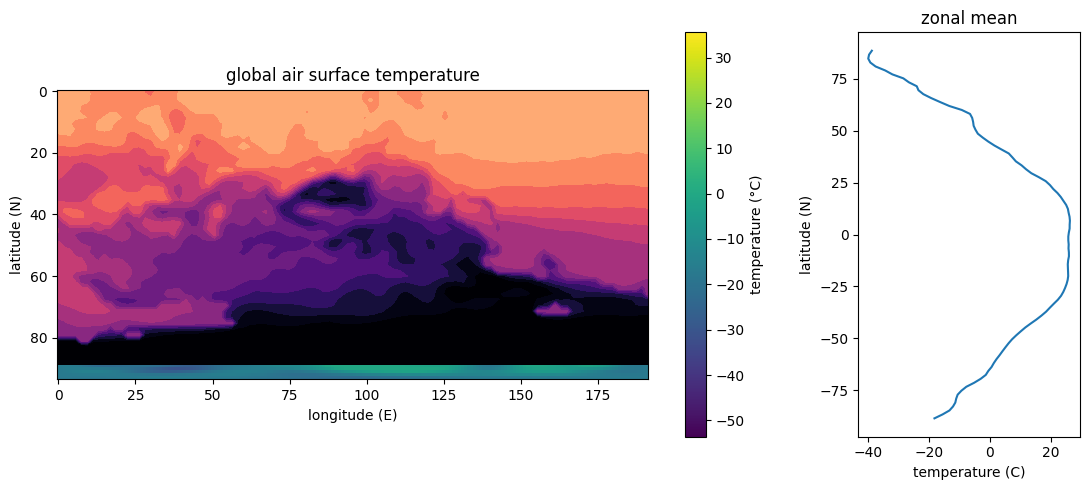

In [ ]:
# Your solution here (wrong codes)
lon = np.load(path_lon)
lat = np.load(path_lat)
temp = np.load(path_temp)
temp_c = temp.astype(float) - 273.15

fig, ax = plt.subplots(1, 2, figsize = (11, 5), gridspec_kw={"width_ratios": [5, 1.5]})

ax[0].contourf(lon, lat, temp_c, levels=np.linspace(-30, 40, 15), cmap="magma", extend="both",
               contour_level=[-10]) # error countour_level
im = ax[0].imshow(temp_c) # should not use imshow
fig.colorbar(im, ax=ax[0], label="temperature (°C)")

ax[1].plot(np.mean(temp_c, axis=1), lat)

ax[0].set_xlabel("longitude (E)")
ax[0].set_ylabel("latitude (N)")
ax[0].set_title("global air surface temperature")

ax[1].set_xlabel("temperature (C)")
ax[1].set_ylabel("latitude (N)")
ax[1].set_title("zonal mean")

plt.tight_layout()

<function matplotlib.pyplot.show(close=None, block=None)>

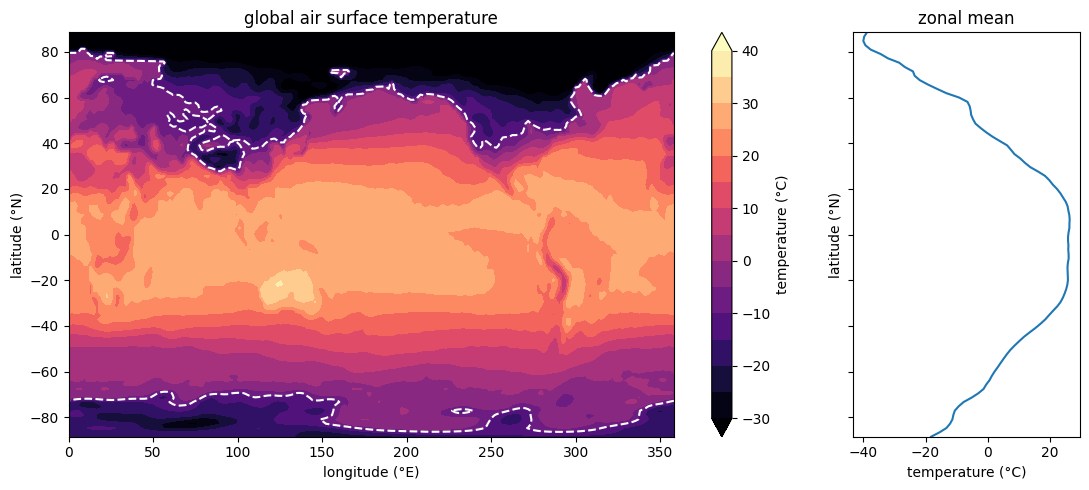

In [ ]:
# Your solution here (corrected codes)
lon = np.load(path_lon)
lat = np.load(path_lat)
temp = np.load(path_temp)
temp_c = temp.astype(float) - 273.15

fig, ax = plt.subplots(1, 2, figsize = (11, 5),
                       gridspec_kw={"width_ratios": [5, 1.5]},
                       sharey=True)

cf = ax[0].contourf(lon, lat, temp_c, levels=np.linspace(-30, 40, 15),
                    cmap="magma", extend="both") # use contourf only, without adding im
ax[0].contour(lon, lat, temp_c, levels=[-10], colors="w")
fig.colorbar(cf, ax=ax[0], label="temperature (°C)")

ax[1].plot(np.mean(temp_c, axis=1), lat)

ax[0].set_xlabel("longitude (°E)")
ax[0].set_ylabel("latitude (°N)")
ax[0].set_title("global air surface temperature")

ax[1].set_xlabel("temperature (°C)")
ax[1].set_ylabel("latitude (°N)")
ax[1].set_title("zonal mean")

plt.tight_layout()
plt.show

## Conclusion

This challenge showed me that a plot can run without raising any error and still be wrong, so **checking the output carefully matters as much as getting the code to execute. :)**